# GA4 Storefront Analytics: Validation & Charts

**Purpose:** independently re-check key SQL results in Python, add confidence intervals, and produce charts for the memo and README.

**Data:** `p3_storefront.sessions` (one row per session, built by `sql/10`) and `p3_storefront.orders` (one row per deduplicated order, built by `sql/21`).

**Rule:** every number here must match the SQL result recorded in the corresponding `sql/` file header.

In [1]:
%pip install --quiet google-cloud-bigquery db-dtypes pandas matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
from google.cloud import bigquery
import pandas as pd

client = bigquery.Client(project="ga4-storefront-analytics")

test = client.query("""
    SELECT COUNT(*) AS sessions
    FROM `ga4-storefront-analytics.p3_storefront.sessions`
""").to_dataframe()

test

/opt/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,sessions
0,360129


In [3]:
from google.cloud import bigquery
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

client = bigquery.Client(project="ga4-storefront-analytics")

# small helper so i don't have to repeat this every time
def run_query(sql):
    return client.query(sql).to_dataframe()

# load the sessions table (1 row per session)
sessions = run_query("""
select *
from `ga4-storefront-analytics.p3_storefront.sessions`
""")

# load the orders table (1 row per deduped order)
orders = run_query("""
select *
from `ga4-storefront-analytics.p3_storefront.orders`
""")

print(sessions.shape)
print(orders.shape)
sessions.head()

(360129, 22)
(5372, 8)


,session_key,user_pseudo_id,ga_session_id,session_date,session_start_ts,ga_session_number,device_category,country,first_touch_medium,events,...,has_add_to_cart,has_begin_checkout,has_add_payment_info,has_purchase,session_medium,session_source,channel_session,channel_first_touch,country_group,visitor_type
0,33471372.4052875372-7440278688,33471372.4052875372,7440278688,2020-11-19,1605772589038681,1,desktop,(not set),organic,5,...,0,0,0,0,None,None,(not captured),Organic Search,Rest of world,New
1,41288043.0153688418-5964489302,41288043.0153688418,5964489302,2020-11-03,1604386861763135,1,desktop,(not set),(none),8,...,0,0,0,0,None,None,(not captured),Direct,Rest of world,New
2,78288554.5382118273-5570932310,78288554.5382118273,5570932310,2021-01-26,1611639757670444,1,desktop,(not set),organic,7,...,0,0,0,0,None,None,(not captured),Organic Search,Rest of world,New
3,5442564.3099959268-4291664754,5442564.3099959268,4291664754,2021-01-07,1609992459860856,1,desktop,(not set),(none),6,...,0,0,0,0,None,None,(not captured),Direct,Rest of world,New
4,15925275.3558252347-2577391675,15925275.3558252347,2577391675,2020-12-26,1608946213148270,1,mobile,(not set),organic,4,...,0,0,0,0,None,None,(not captured),Organic Search,Rest of world,New


## 1. Validation: do the Python numbers match the SQL?

In [4]:
# numbers i got from the sql queries (copied from the sql file headers)
expected = {
    "sessions": 360129,               # sql/11
    "session_start_events": 354970,   # sql/11
    "purchasing_sessions": 4848,      # sql/11
    "funnel_view_item": 77020,        # sql/15
    "funnel_checkout": 10825,         # sql/15
    "funnel_payment": 6606,           # sql/15
    "funnel_purchase": 4698,          # sql/15
    "orders": 5372,                   # sql/22
    "revenue": 340647,                # sql/22
    "unverified_orders": 906,         # sql/22
    "buyers": 4419,                   # sql/22
}

# funnel v2 steps (closed funnel, each step needs the one before it)
viewed = sessions["has_view_item"] == 1
checkout = viewed & (sessions["has_begin_checkout"] == 1)
payment = checkout & (sessions["has_add_payment_info"] == 1)
purchase = payment & (sessions["has_purchase"] == 1)

# same numbers but calculated in pandas
actual = {
    "sessions": len(sessions),
    "session_start_events": sessions["session_start_events"].sum(),
    "purchasing_sessions": sessions["has_purchase"].sum(),
    "funnel_view_item": viewed.sum(),
    "funnel_checkout": checkout.sum(),
    "funnel_payment": payment.sum(),
    "funnel_purchase": purchase.sum(),
    "orders": len(orders),
    "revenue": round(orders["revenue_usd"].sum()),
    "unverified_orders": orders["is_unverified_id"].sum(),
    "buyers": orders["user_pseudo_id"].nunique(),
}

check = pd.DataFrame({"sql": expected, "python": actual})
check["match"] = check["sql"] == check["python"]
check

,sql,python,match
sessions,360129,360129,True
session_start_events,354970,354970,True
purchasing_sessions,4848,4848,True
funnel_view_item,77020,77020,True
funnel_checkout,10825,10825,True
funnel_payment,6606,6606,True
funnel_purchase,4698,4698,True
orders,5372,5372,True
revenue,340647,340647,True
unverified_orders,906,906,True


## 2. How sure are we? Confidence intervals

In [5]:
import numpy as np

# conversion by visitor type, using funnel v2 purchases from the cell above
df = sessions.assign(purchased=purchase.astype(int))
conv = df.groupby("visitor_type")["purchased"].agg(["sum", "count"])
conv["rate"] = conv["sum"] / conv["count"]

# 95% confidence interval for each rate (normal approximation)
z = 1.96
se = np.sqrt(conv["rate"] * (1 - conv["rate"]) / conv["count"])
conv["ci_low"] = conv["rate"] - z * se
conv["ci_high"] = conv["rate"] + z * se

# show as percentages
print((conv[["rate", "ci_low", "ci_high"]] * 100).round(2))

# 95% ci for the gap (returning minus new)
p_ret, n_ret = conv.loc["Returning", "rate"], conv.loc["Returning", "count"]
p_new, n_new = conv.loc["New", "rate"], conv.loc["New", "count"]
gap = p_ret - p_new
gap_se = np.sqrt(p_ret * (1 - p_ret) / n_ret + p_new * (1 - p_new) / n_new)
print(f"\ngap: {gap*100:.2f} pts, 95% ci: {(gap - z*gap_se)*100:.2f} to {(gap + z*gap_se)*100:.2f} pts")

              rate  ci_low  ci_high
visitor_type                       
New           0.67    0.64     0.70
Returning     2.97    2.87     3.08

gap: 2.30 pts, 95% ci: 2.19 to 2.41 pts


In [6]:
# get 30-day revenue per new user + their acquisition channel (same logic as sql/24)
users = run_query("""
with first_seen as (
  select
    user_pseudo_id,
    min(session_date) as first_date,
    array_agg(struct(ga_session_number, channel_first_touch as channel)
              order by session_start_ts limit 1)[safe_offset(0)] as fs
  from `ga4-storefront-analytics.p3_storefront.sessions`
  group by user_pseudo_id
),
new_users as (
  select user_pseudo_id, first_date, fs.channel as acq_channel
  from first_seen
  where fs.ga_session_number = 1
    and first_date between '2020-11-02' and '2021-01-02'
)
select
  u.user_pseudo_id,
  u.acq_channel,
  sum(if(date_diff(o.order_date, u.first_date, day) <= 29, o.revenue_usd, 0)) as rev_d30
from new_users u
left join `ga4-storefront-analytics.p3_storefront.orders` o
  using (user_pseudo_id)
group by u.user_pseudo_id, u.acq_channel
""")

# quick check: these should match sql/24 (paid 1.48, organic 1.31)
print(len(users))
print(users.groupby("acq_channel")["rev_d30"].mean().round(2))

# bootstrap: resample each group 2000 times and look at the difference in means
paid = users.loc[users["acq_channel"] == "Paid Search", "rev_d30"].values
organic = users.loc[users["acq_channel"] == "Organic Search", "rev_d30"].values

rng = np.random.default_rng(42)  # fixed seed so results are repeatable
diffs = []
for i in range(2000):
    paid_sample = rng.choice(paid, size=len(paid), replace=True)
    organic_sample = rng.choice(organic, size=len(organic), replace=True)
    diffs.append(paid_sample.mean() - organic_sample.mean())

low, high = np.percentile(diffs, [2.5, 97.5])
print(f"\npaid - organic: ${paid.mean() - organic.mean():.2f}, 95% ci: ${low:.2f} to ${high:.2f}")

173023
acq_channel
Direct            1.11
Organic Search    1.31
Paid Search       1.48
Referral          1.18
Unknown           1.21
Name: rev_d30, dtype: float64

paid - organic: $0.17, 95% ci: $-0.26 to $0.64


**Result:** Paid Search users look like they're worth more in 30 days than Organic users (+$0.17), but the 95% bootstrap CI is -$0.26 to +$0.64, which includes 0. With only ~156 paid buyers this difference could just be noise, so I'm not claiming Paid Search is the most valuable channel. Channel value looks statistically similar.

## 3. Charts

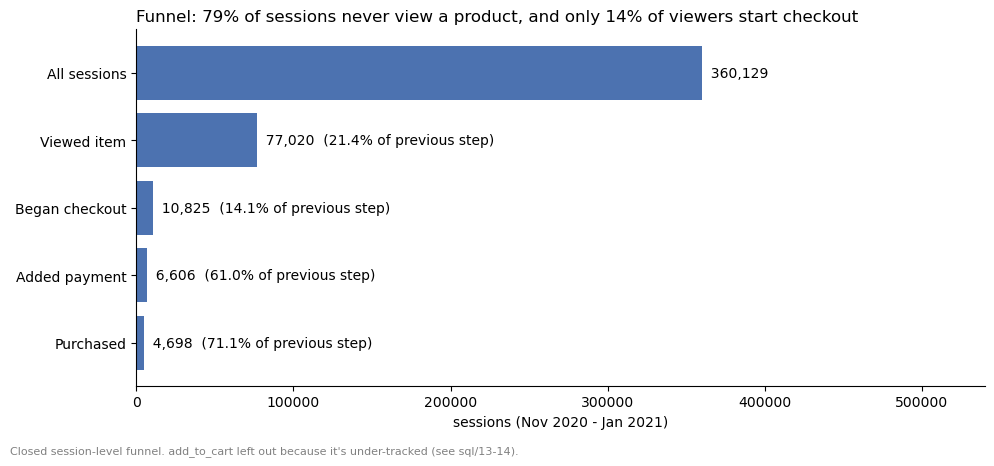

In [7]:
import matplotlib.pyplot as plt
import os

# folder in the repo to save chart images (notebook is inside notebooks/, so go up one level)
os.makedirs("../images", exist_ok=True)

steps = ["All sessions", "Viewed item", "Began checkout", "Added payment", "Purchased"]
counts = [len(sessions), viewed.sum(), checkout.sum(), payment.sum(), purchase.sum()]

fig, ax = plt.subplots(figsize=(10, 4.5))
# barh draws bottom-up, so reverse the lists to put "All sessions" on top
ax.barh(steps[::-1], counts[::-1], color="#4c72b0")

# write the count and the step rate next to each bar
for i, c in enumerate(counts):
    y = len(steps) - 1 - i
    if i == 0:
        label = f"{c:,}"
    else:
        label = f"{c:,}  ({c / counts[i-1]:.1%} of previous step)"
    ax.text(c, y, "  " + label, va="center")

ax.set_title("Funnel: 79% of sessions never view a product, and only 14% of viewers start checkout", loc="left")
ax.set_xlabel("sessions (Nov 2020 - Jan 2021)")
ax.set_xlim(0, counts[0] * 1.5)
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.02, "Closed session-level funnel. add_to_cart left out because it's under-tracked (see sql/13-14).",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/01_funnel.png", dpi=150, bbox_inches="tight")
plt.show()

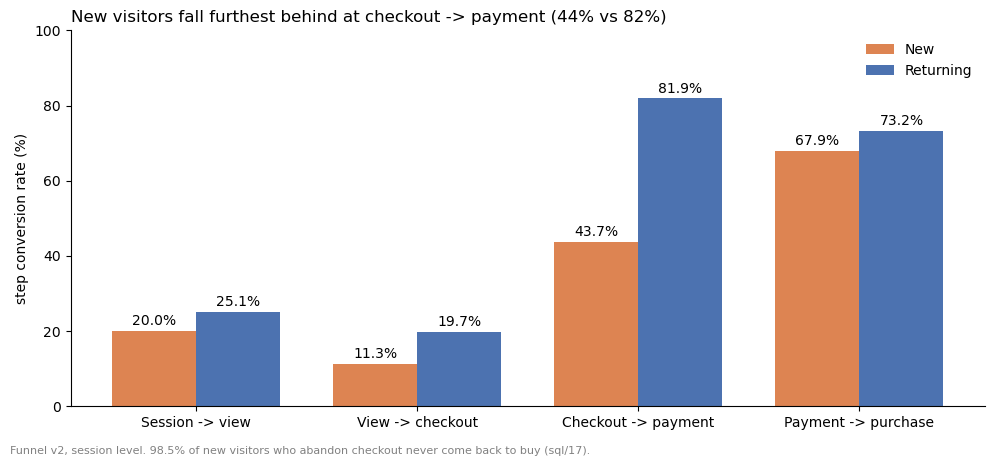

In [8]:
# step rates for new vs returning visitors
labels = ["Session -> view", "View -> checkout", "Checkout -> payment", "Payment -> purchase"]
rates = {}

for vt in ["New", "Returning"]:
    is_vt = sessions["visitor_type"] == vt
    n_sessions = is_vt.sum()
    n_view = (viewed & is_vt).sum()
    n_checkout = (checkout & is_vt).sum()
    n_payment = (payment & is_vt).sum()
    n_purchase = (purchase & is_vt).sum()
    rates[vt] = [n_view / n_sessions, n_checkout / n_view,
                 n_payment / n_checkout, n_purchase / n_payment]

x = np.arange(len(labels))
w = 0.38

fig, ax = plt.subplots(figsize=(10, 4.5))
bars_new = ax.bar(x - w/2, np.array(rates["New"]) * 100, w, label="New", color="#dd8452")
bars_ret = ax.bar(x + w/2, np.array(rates["Returning"]) * 100, w, label="Returning", color="#4c72b0")

# print the % on top of each bar
ax.bar_label(bars_new, fmt="%.1f%%", padding=2)
ax.bar_label(bars_ret, fmt="%.1f%%", padding=2)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("step conversion rate (%)")
ax.set_ylim(0, 100)
ax.set_title("New visitors fall furthest behind at checkout -> payment (44% vs 82%)", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.02, "Funnel v2, session level. 98.5% of new visitors who abandon checkout never come back to buy (sql/17).",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/02_new_vs_returning.png", dpi=150, bbox_inches="tight")
plt.show()

   sessions  conv_pct  revenue
5     38729      1.99  59366.0


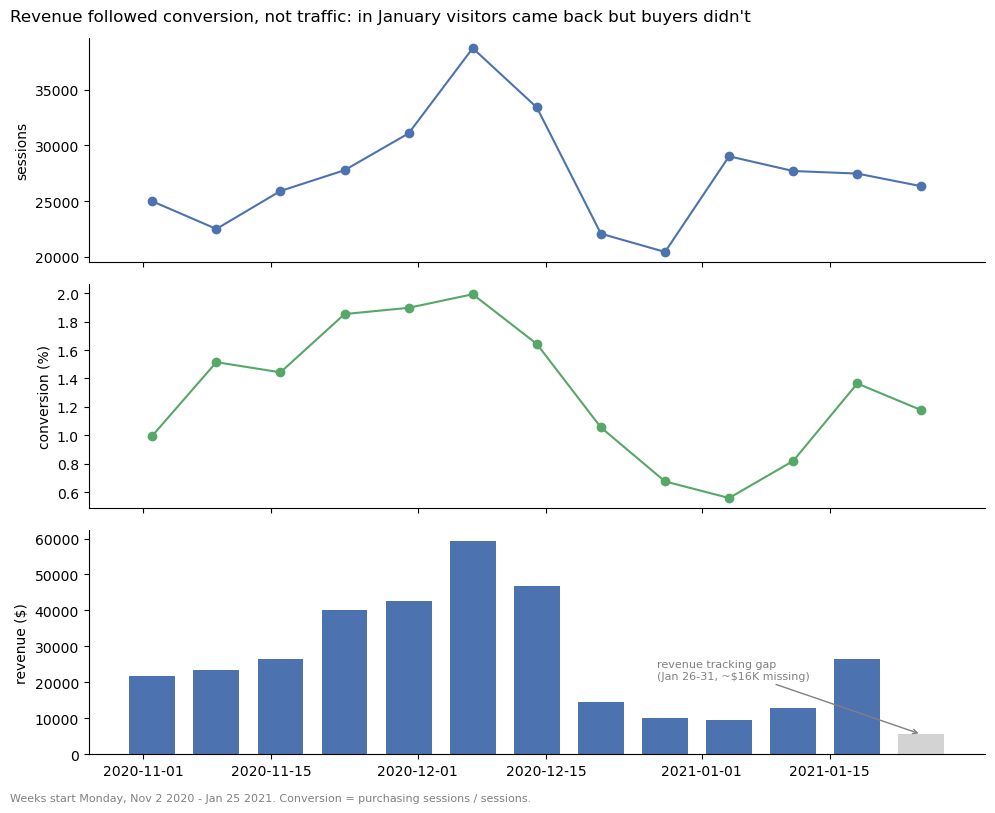

In [9]:
# make sure the date columns are real dates
sessions["session_date"] = pd.to_datetime(sessions["session_date"])
orders["order_date"] = pd.to_datetime(orders["order_date"])

# 13 full weeks starting monday nov 2 (same as sql/28)
s = sessions[sessions["session_date"] >= "2020-11-02"].copy()
o = orders[orders["order_date"] >= "2020-11-02"].copy()

# week = the monday of that week
s["week"] = s["session_date"].dt.to_period("W-SUN").dt.start_time
o["week"] = o["order_date"].dt.to_period("W-SUN").dt.start_time

weekly = s.groupby("week").agg(sessions=("session_key", "count"),
                               buying_sessions=("has_purchase", "sum"))
weekly["conv_pct"] = weekly["buying_sessions"] / weekly["sessions"] * 100
weekly["revenue"] = o.groupby("week")["revenue_usd"].sum()
weekly = weekly.reset_index()

# quick check against sql/28 for the peak week (expect 38729 sessions, 1.99%, 59366)
print(weekly[weekly["week"] == "2020-12-07"][["sessions", "conv_pct", "revenue"]].round(2))

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(weekly["week"], weekly["sessions"], marker="o", color="#4c72b0")
axes[0].set_ylabel("sessions")

axes[1].plot(weekly["week"], weekly["conv_pct"], marker="o", color="#55a868")
axes[1].set_ylabel("conversion (%)")

# last week's revenue is broken (tracking gap), so make it gray
colors = ["#4c72b0"] * (len(weekly) - 1) + ["lightgray"]
axes[2].bar(weekly["week"], weekly["revenue"], width=5, color=colors)
axes[2].set_ylabel("revenue ($)")
axes[2].annotate("revenue tracking gap\n(Jan 26-31, ~$16K missing)",
                 xy=(weekly["week"].iloc[-1], weekly["revenue"].iloc[-1]),
                 xytext=(-190, 40), textcoords="offset points",
                 arrowprops=dict(arrowstyle="->", color="gray"), fontsize=8, color="gray")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Revenue followed conversion, not traffic: in January visitors came back but buyers didn't",
             x=0.01, ha="left")
fig.text(0.01, -0.01, "Weeks start Monday, Nov 2 2020 - Jan 25 2021. Conversion = purchasing sessions / sessions.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/03_weekly_trends.png", dpi=150, bbox_inches="tight")
plt.show()

                                  First-touch  Last-touch (raw)  \
Organic Search                           28.9              32.0   
Referral                                 23.1              53.5   
Direct                                   21.9               6.7   
Unknown                                  23.7               6.3   
Paid Search                               2.5               0.9   
Self-referral (no prior channel)          0.0               0.0   
(not captured)                            0.0               0.0   
Other                                     0.0               0.5   

                                  Last-touch (cleaned)  
Organic Search                                    42.0  
Referral                                          26.5  
Direct                                             8.7  
Unknown                                            7.9  
Paid Search                                        1.4  
Self-referral (no prior channel)                   9.1

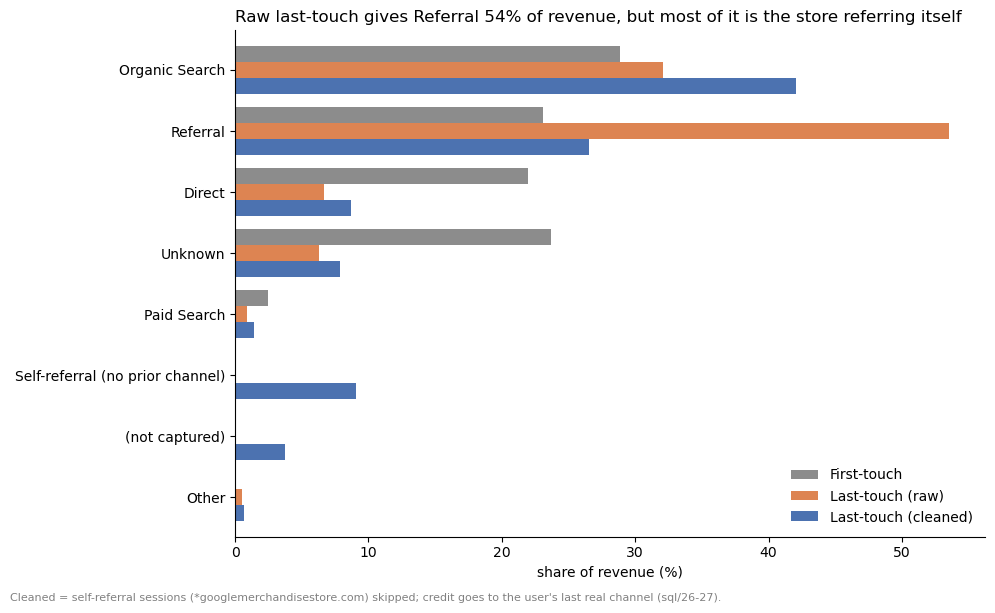

In [10]:
# sort each user's sessions in time order
ses = sessions.sort_values(["user_pseudo_id", "session_start_ts"]).copy()

# self-referral = "Referral" session whose source is the store's own domain
ses["is_self_ref"] = (ses["channel_session"] == "Referral") & \
                     ses["session_source"].fillna("").str.endswith("googlemerchandisestore.com")

# cleaned channel: blank out self-referrals, then carry the last real channel forward per user
ses["clean_channel"] = ses["channel_session"].where(~ses["is_self_ref"])
ses["clean_channel"] = ses.groupby("user_pseudo_id")["clean_channel"].ffill()
ses["clean_channel"] = ses["clean_channel"].fillna("Self-referral (no prior channel)")

# attach channels to each order
att = orders.merge(ses[["session_key", "channel_first_touch", "channel_session", "clean_channel"]],
                   on="session_key")

def revenue_share(col):
    return att.groupby(col)["revenue_usd"].sum() / att["revenue_usd"].sum() * 100

order = ["Organic Search", "Referral", "Direct", "Unknown", "Paid Search",
         "Self-referral (no prior channel)", "(not captured)", "Other"]

shares = pd.DataFrame({
    "First-touch": revenue_share("channel_first_touch"),
    "Last-touch (raw)": revenue_share("channel_session"),
    "Last-touch (cleaned)": revenue_share("clean_channel"),
}).reindex(order).fillna(0)

# check vs sql/27 (organic 28.9 / 32.0 / 42.0, referral 23.1 / 53.5 / 26.5)
print(shares.round(1))

ax = shares.plot(kind="barh", figsize=(10, 6), width=0.8,
                 color=["#8c8c8c", "#dd8452", "#4c72b0"])
ax.invert_yaxis()
ax.set_xlabel("share of revenue (%)")
ax.set_ylabel("")
ax.set_title("Raw last-touch gives Referral 54% of revenue, but most of it is the store referring itself",
             loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.figtext(0.01, -0.01, "Cleaned = self-referral sessions (*googlemerchandisestore.com) skipped; "
            "credit goes to the user's last real channel (sql/26-27).", fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/04_attribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Summary

- All 11 headline numbers (sessions, funnel, orders, revenue, buyers) match the SQL results exactly.
- The attribution carry-forward logic (sql/27) was rebuilt in pandas with groupby + ffill and matches exactly.
- New vs returning conversion gap: 2.30 pts (95% CI 2.19 to 2.41), so it's real.
- Paid vs Organic 30-day LTV: +$0.17 (95% bootstrap CI -$0.26 to +$0.64), not significant, so channel value is treated as similar.
- Charts saved to `images/` for the README and memo.